In [1]:
import pandas as pd
import numpy as np

data = pd.read_csv("4820_FinalProjectCleaned.csv")

In [14]:

import pandas as pd
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Always include these 6 features
fixed_features = [
    "Market Share",
    "Passenger Load Factor",
    "OTP Index",
    "Hourly_Airport_Departures",
    "Distance",
    "Airport_Congestion_Index"
]

# Select the best combination of weather features
weather_features = [
    "VC_windspeed",
    "VC_cloudcover",
    "VC_visibility",
    "VC_temp",
    "VC_humidity",
    "VC_precip",
    "VC_2h_temp",
    "VC_2h_humidity",
    "VC_2h_precip",
    "VC_2h_windspeed",
    "VC_2h_visibility"
]

significant_features = [
    "VC_windspeed",
    "VC_cloudcover",
    "VC_visibility",
    "VC_temp",
    "VC_humidity",
    "VC_precip",
    "VC_2h_temp",
    "VC_2h_humidity",
    "VC_2h_precip",
    "VC_2h_windspeed",
    "VC_2h_visibility",
    "Market Share",
    "Passenger Load Factor",
    "OTP Index",
    "Hourly_Airport_Departures",
    "Distance",
    "Airport_Congestion_Index"
]

X = data[significant_features].copy()
X = X.apply(pd.to_numeric, errors="coerce")

y = (data["Departure Delay"] > 0).astype(int)

# Random Forest model
model = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )),
    ("rf", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Forward selection
selector = SFS(
    model,
    k_features="best",
    forward=True,
    floating=False,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    fixed_features=tuple(fixed_features)
)

# Run selection
selector.fit(X, y)

# Selected features
best_features = list(dict.fromkeys(
    selector.k_feature_names_
))

print("BEST RANDOM FOREST FEATURES:")
print(best_features)

print("\nNumber of features:", len(best_features))
print("Best CV F1:", selector.k_score_)

# Compare against all features
all_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("\nAll features F1:", all_scores.mean())
print("Selected features F1:", selector.k_score_)


BEST RANDOM FOREST FEATURES:
['Market Share', 'Passenger Load Factor', 'OTP Index', 'Hourly_Airport_Departures', 'Distance', 'Airport_Congestion_Index']

Number of features: 6
Best CV F1: 0.6986087400837617

All features F1: 0.6844677314790835
Selected features F1: 0.6986087400837617


In [ ]:
weather_cols = [
    c for c in data.columns
    if c.startswith(("weather__hourly__", "Past_"))
]

other_cols = [
    "Market Share",
    "Passenger Load Factor",
    "Distance",
    "OTP Index",
    "Airport_Congestion_Index",
    "Hourly_Airport_Departures"
]

X = data[weather_cols + other_cols].copy()
y = data["Is_Delayed"]

# Treat weather codes as categories
X["Past_weatherDesc"] = X["Past_weatherDesc"].astype(str)

# Encode categorical variables
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Flights:", X.shape[0])
print("Features:", X.shape[1])

Number of features: 17

Features used:
['VC_windspeed', 'VC_cloudcover', 'VC_visibility', 'VC_temp', 'VC_humidity', 'VC_precip', 'VC_2h_temp', 'VC_2h_humidity', 'VC_2h_precip', 'VC_2h_windspeed', 'VC_2h_visibility', 'Market Share', 'Passenger Load Factor', 'OTP Index', 'Hourly_Airport_Departures', 'Distance', 'Airport_Congestion_Index']

RANDOM FOREST RESULTS
-------------------------
Accuracy: 0.6942
Precision: 0.6894
Recall: 0.6833
F1: 0.6863

Training F1: 0.8051641443806303
Validation F1: 0.6863085417459416
F1 Gap: 0.11885560263468875


In [21]:

import pandas as pd
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# ==========================================
# 1. FIXED FEATURES (ALWAYS INCLUDED)
# ==========================================

fixed_features = [
    "Market Share",
    "Passenger Load Factor",
    "OTP Index",
    "Hourly_Airport_Departures",
    "Distance",
    "Airport_Congestion_Index"
]

# ==========================================
# 2. WEATHER FEATURES TO TEST
# ==========================================

weather_features = [
    "VC_windspeed",
    "VC_cloudcover",
    "VC_visibility",
    "VC_temp",
    "VC_humidity",
    "VC_precip",
    "VC_2h_temp",
    "VC_2h_humidity",
    "VC_2h_precip",
    "VC_2h_windspeed",
    "VC_2h_visibility"
]

features = fixed_features + weather_features

# ==========================================
# 3. PREPARE DATA
# ==========================================

X_full = data[features].apply(
    pd.to_numeric, errors="coerce"
)

y = (data["Departure Delay"] > 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_full,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# ==========================================
# 4. RANDOM FOREST MODEL
# ==========================================

# Change these hyperparameters if desired
rf_model = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )),
    ("rf", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=1
    ))
])

# ==========================================
# 5. FORWARD FEATURE SELECTION
# ==========================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

selector = SFS(
    rf_model,
    k_features="best",
    forward=True,
    floating=False,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    fixed_features=tuple(fixed_features)
)

print("Running forward feature selection...")

selector.fit(X_train, y_train)

# ==========================================
# 6. TOP 10 FEATURE COMBINATIONS
# ==========================================

results = []

for step, info in selector.subsets_.items():

    selected = list(dict.fromkeys(info["feature_names"]))

    selected_weather = [
        f for f in selected
        if f in weather_features
    ]

    results.append({
        "Number of Features": len(selected),
        "Weather Features": ", ".join(selected_weather),
        "All Features": selected,
        "CV F1": info["avg_score"]
    })

top_10 = pd.DataFrame(results).sort_values(
    "CV F1",
    ascending=False
).head(10).reset_index(drop=True)

top_10.index += 1
top_10.index.name = "Rank"

print("\nTOP 10 RANDOM FOREST FEATURE COMBINATIONS")
display(top_10)

# ==========================================
# 7. BEST COMBINATION
# ==========================================

best_features = top_10.iloc[0]["All Features"]

print("\nBEST FEATURE COMBINATION:")
print(best_features)

print("\nNumber of Features:", len(best_features))
print("Best CV F1:", round(top_10.iloc[0]["CV F1"], 4))


Running forward feature selection...

TOP 10 RANDOM FOREST FEATURE COMBINATIONS


,Number of Features,Weather Features,All Features,CV F1
Rank,,,,
1,6,,"[Market Share, Passenger Load Factor, OTP Inde...",0.696892
2,10,"VC_windspeed, VC_temp, VC_precip, VC_2h_temp","[Market Share, Passenger Load Factor, OTP Inde...",0.694883
3,9,"VC_windspeed, VC_temp, VC_2h_temp","[Market Share, Passenger Load Factor, OTP Inde...",0.693382
4,11,"VC_windspeed, VC_temp, VC_precip, VC_2h_temp, ...","[Market Share, Passenger Load Factor, OTP Inde...",0.691471
5,7,VC_temp,"[Market Share, Passenger Load Factor, OTP Inde...",0.691338
6,8,"VC_temp, VC_2h_temp","[Market Share, Passenger Load Factor, OTP Inde...",0.690486
7,12,"VC_windspeed, VC_temp, VC_precip, VC_2h_temp, ...","[Market Share, Passenger Load Factor, OTP Inde...",0.688628
8,13,"VC_windspeed, VC_temp, VC_precip, VC_2h_temp, ...","[Market Share, Passenger Load Factor, OTP Inde...",0.683988
9,16,"VC_windspeed, VC_cloudcover, VC_visibility, VC...","[Market Share, Passenger Load Factor, OTP Inde...",0.681086



BEST FEATURE COMBINATION:
['Market Share', 'Passenger Load Factor', 'OTP Index', 'Hourly_Airport_Departures', 'Distance', 'Airport_Congestion_Index']

Number of Features: 6
Best CV F1: 0.6969


In [22]:
# Get second-best combination
second_best = top_10.iloc[1]

second_best_features = second_best["All Features"]

print("SECOND BEST FEATURE COMBINATION:")
print(second_best_features)

print("\nNumber of Features:", len(second_best_features))
print("CV F1:", round(second_best["CV F1"], 4))

print("\nWeather Features:")
print(second_best["Weather Features"])

SECOND BEST FEATURE COMBINATION:
['Market Share', 'Passenger Load Factor', 'OTP Index', 'Hourly_Airport_Departures', 'Distance', 'Airport_Congestion_Index', 'VC_windspeed', 'VC_temp', 'VC_precip', 'VC_2h_temp']

Number of Features: 10
CV F1: 0.6949

Weather Features:
VC_windspeed, VC_temp, VC_precip, VC_2h_temp


In [24]:
#DO FOR KNN
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Your 17 features
significant_features = ['Market Share', 'Passenger Load Factor', 'OTP Index', 
                        'Hourly_Airport_Departures', 'Distance', 'Airport_Congestion_Index', 
                        'VC_windspeed', 'VC_temp', 'VC_precip', 'VC_2h_temp']

X = data[significant_features].apply(
    pd.to_numeric, errors="coerce"
)

y = (data["Departure Delay"] > 0).astype(int)

# Hold out 20% for final testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

model = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )),
    ("rf", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter combinations
param_grid = {
    "rf__n_estimators": [100, 200, 300, 500, 1000, 5000],
    "rf__max_depth": [5, 10, 20, None],
    "rf__min_samples_split": [2, 5, 10],
    "rf__min_samples_leaf": [1, 2, 5, 10],
    "rf__max_features": ["sqrt", "log2", 0.5],
    "rf__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

search.fit(X_train, y_train)

print("BEST PARAMETERS:")
print(search.best_params_)

print("\nBest CV F1:", search.best_score_)

# Evaluate on test set
best_rf = search.best_estimator_
y_pred = best_rf.predict(X_test)

print("\nTEST RESULTS")
print("----------------")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Fitting 5 folds for each of 30 candidates, totalling 150 fits


c:\Users\iacom\anaconda3\envs\ml\lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


BEST PARAMETERS:
{'rf__n_estimators': 500, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 5, 'rf__max_features': 0.5, 'rf__max_depth': 10, 'rf__class_weight': 'balanced'}

Best CV F1: 0.7016533858188986

TEST RESULTS
----------------
Accuracy: 0.7017883035282745
Precision: 0.677737881508079
Recall: 0.7453109575518263
F1: 0.7099200752233192

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.66      0.69      1056
           1       0.68      0.75      0.71      1013

    accuracy                           0.70      2069
   macro avg       0.70      0.70      0.70      2069
weighted avg       0.70      0.70      0.70      2069



RANDOM FOREST RESULTS
Number of features: 10

Training F1: 0.7622
Test Accuracy: 0.7028
Test Precision: 0.6856
Test Recall: 0.7256
Test F1: 0.705

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.68      0.70      1056
           1       0.69      0.73      0.71      1013

    accuracy                           0.70      2069
   macro avg       0.70      0.70      0.70      2069
weighted avg       0.70      0.70      0.70      2069


5-FOLD CROSS-VALIDATION
Accuracy: 0.6967
Precision: 0.6821
Recall: 0.7132
F1: 0.6972

CV Training F1: 0.7703
CV Validation F1: 0.6972
CV F1 Gap: 0.0731


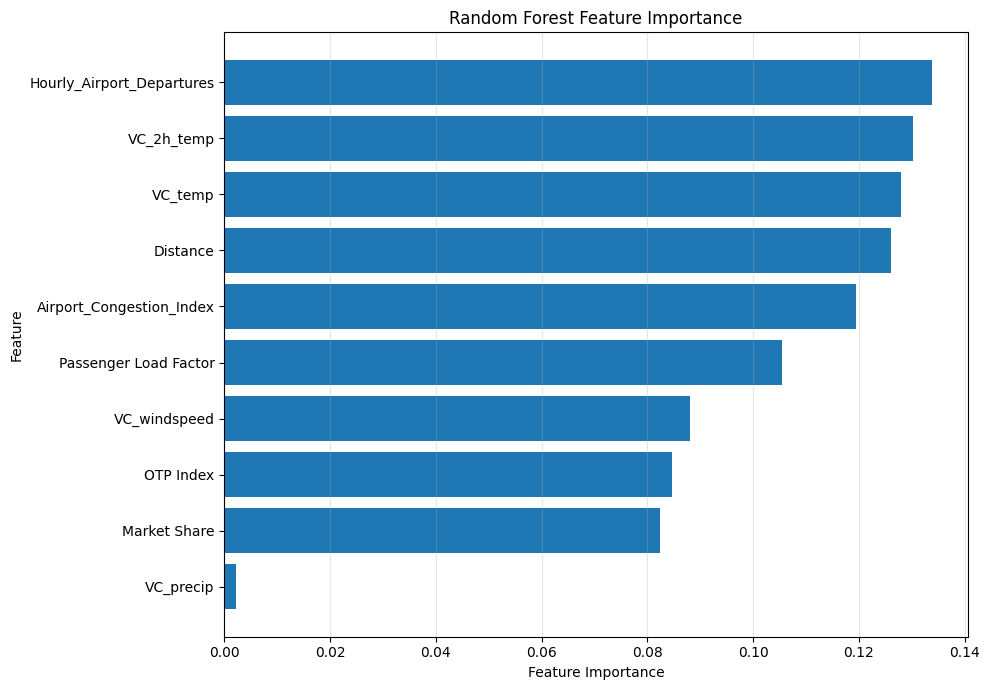


FEATURE IMPORTANCE
                  Feature  Importance
Hourly_Airport_Departures    0.133833
               VC_2h_temp    0.130162
                  VC_temp    0.127982
                 Distance    0.126060
 Airport_Congestion_Index    0.119471
    Passenger Load Factor    0.105351
             VC_windspeed    0.088041
                OTP Index    0.084603
             Market Share    0.082342
                VC_precip    0.002155


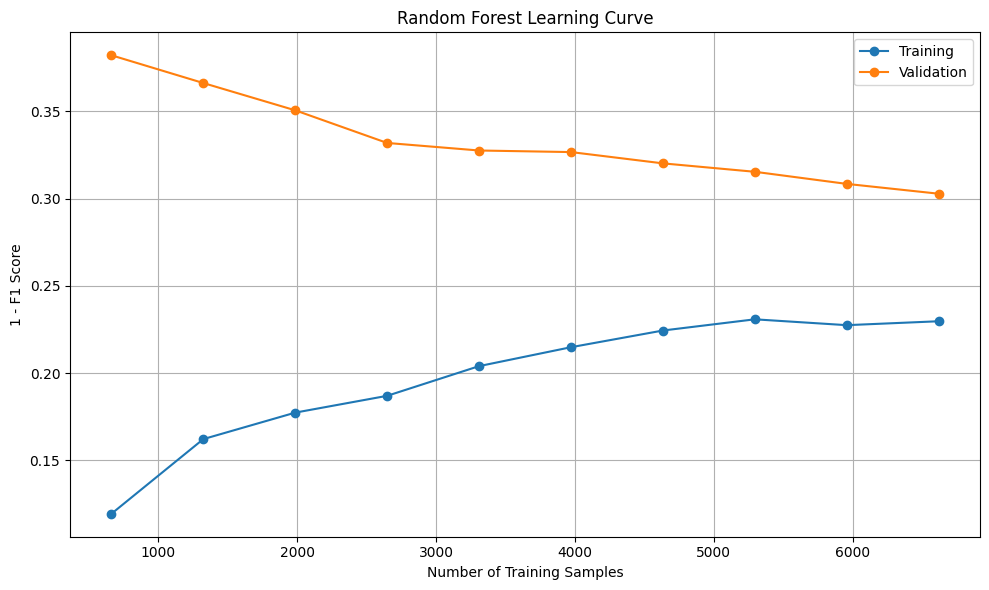


LEARNING CURVE RESULTS
Final Training F1: 0.7703
Final Validation F1: 0.6972


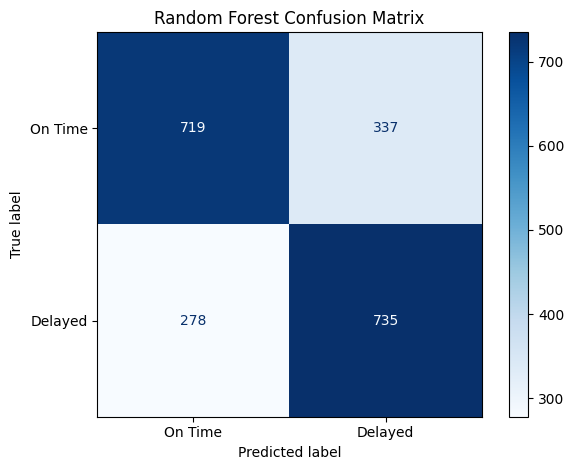

In [25]:
#Find best hyper paramters for those features
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    learning_curve
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. FEATURES - EDIT THESE
# ==========================================

significant_features = ['Market Share', 'Passenger Load Factor', 'OTP Index', 
                        'Hourly_Airport_Departures', 'Distance', 'Airport_Congestion_Index', 
                        'VC_windspeed', 'VC_temp', 'VC_precip', 'VC_2h_temp']

significant_features = list(dict.fromkeys(significant_features))

X = data[significant_features].apply(
    pd.to_numeric, errors="coerce"
)

y = (data["Departure Delay"] > 0).astype(int)

# ==========================================
# 2. HYPERPARAMETERS - EDIT THESE
# ==========================================

n_estimators = 500
max_depth = 10
min_samples_split = 2
min_samples_leaf = 5
max_features = 0.5

rf_model = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )),
    ("rf", RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=42,
        n_jobs=1
    ))
])

# ==========================================
# 3. TRAIN / TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

print("RANDOM FOREST RESULTS")
print("=" * 40)

print("Number of features:", len(significant_features))

print("\nTraining F1:",
      round(f1_score(y_train, y_train_pred), 4))

print("Test Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Test Precision:",
      round(precision_score(y_test, y_test_pred), 4))

print("Test Recall:",
      round(recall_score(y_test, y_test_pred), 4))

print("Test F1:",
      round(f1_score(y_test, y_test_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# ==========================================
# 4. CROSS-VALIDATION
# ==========================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"],
    return_train_score=True,
    n_jobs=-1
)

print("\n5-FOLD CROSS-VALIDATION")
print("=" * 40)

for metric in ["accuracy", "precision", "recall", "f1"]:
    print(
        f"{metric.capitalize()}: "
        f"{cv_scores['test_' + metric].mean():.4f}"
    )

print("\nCV Training F1:",
      round(cv_scores["train_f1"].mean(), 4))

print("CV Validation F1:",
      round(cv_scores["test_f1"].mean(), 4))

print("CV F1 Gap:",
      round(
          cv_scores["train_f1"].mean()
          - cv_scores["test_f1"].mean(), 4
      ))

# ==========================================
# 5. FEATURE IMPORTANCE
# ==========================================

importances = rf_model.named_steps["rf"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": significant_features,
    "Importance": importances
}).sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nFEATURE IMPORTANCE")
print(
    importance_df.sort_values(
        "Importance", ascending=False
    ).to_string(index=False)
)

# ==========================================
# 6. LEARNING CURVE
# ==========================================

train_sizes, train_scores, val_scores = learning_curve(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

train_loss = 1 - train_scores.mean(axis=1)
val_loss = 1 - val_scores.mean(axis=1)

plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    train_loss,
    marker="o",
    label="Training"
)

plt.plot(
    train_sizes,
    val_loss,
    marker="o",
    label="Validation"
)

plt.xlabel("Number of Training Samples")
plt.ylabel("1 - F1 Score")
plt.title("Random Forest Learning Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nLEARNING CURVE RESULTS")
print("Final Training F1:", round(1 - train_loss[-1], 4))
print("Final Validation F1:", round(1 - val_loss[-1], 4))

# ==========================================
# 7. CONFUSION MATRIX
# ==========================================

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["On Time", "Delayed"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


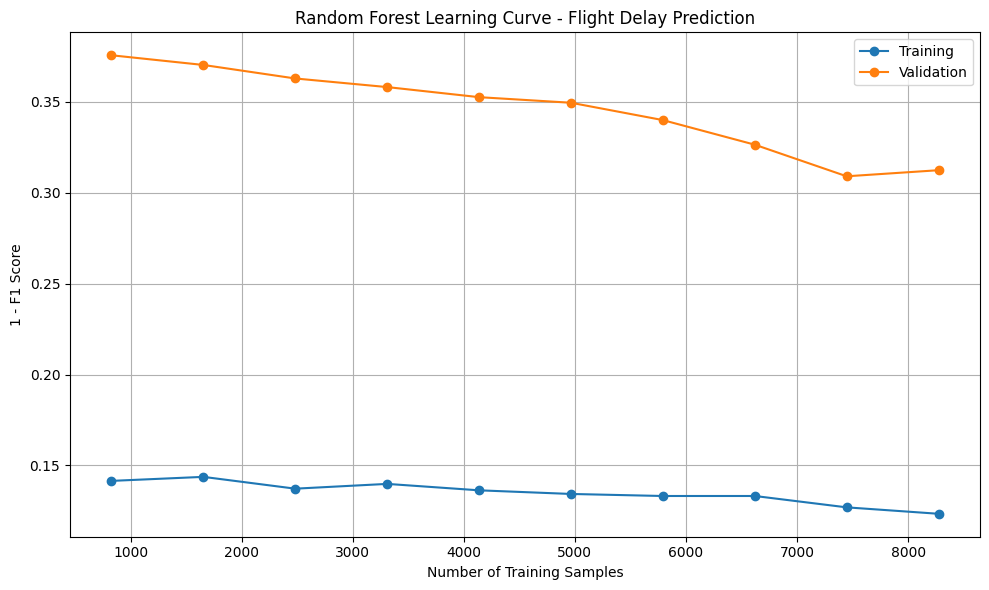

Final Training F1: 0.8765545721948602
Final Validation F1: 0.687671841700015
F1 Gap: 0.18888273049484516


In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# All 17 features
significant_features = [
    "VC_windspeed",
    "VC_cloudcover",
    "VC_visibility",
    "VC_temp",
    "VC_humidity",
    "VC_precip",
    "VC_2h_temp",
    "VC_2h_humidity",
    "VC_2h_precip",
    "VC_2h_windspeed",
    "VC_2h_visibility",
    "Market Share",
    "Passenger Load Factor",
    "OTP Index",
    "Hourly_Airport_Departures",
    "Distance",
    "Airport_Congestion_Index"
]

X = data[significant_features].apply(
    pd.to_numeric, errors="coerce"
)

y = (data["Departure Delay"] > 0).astype(int)

# Use tuned forest if available, otherwise baseline
if "best_rf" in globals():
    rf_model = best_rf
else:
    rf_model = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )),
        ("rf", RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=1
        ))
    ])

# Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate learning curve
train_sizes, train_scores, val_scores = learning_curve(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# Convert F1 scores into error
train_loss = 1 - train_scores.mean(axis=1)
val_loss = 1 - val_scores.mean(axis=1)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    train_loss,
    marker="o",
    label="Training"
)

plt.plot(
    train_sizes,
    val_loss,
    marker="o",
    label="Validation"
)

plt.xlabel("Number of Training Samples")
plt.ylabel("1 - F1 Score")
plt.title("Random Forest Learning Curve - Flight Delay Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Print final values
print("Final Training F1:", 1 - train_loss[-1])
print("Final Validation F1:", 1 - val_loss[-1])
print("F1 Gap:", val_loss[-1] - train_loss[-1])
